# Chapter 07: Compression & Hierarchy
### Partial Pooling and the Information Bottleneck

> *"The purpose of abstraction is not to be vague, but to create a new
> semantic level, in which one can be absolutely precise."*
> — Edsger W. Dijkstra

In the previous chapter, we explored Markov Chain Monte Carlo (MCMC) as an
ergodic sampling engine navigating the typical set where parameter probability
density balances state-space volume. We analyzed individual test endpoints or
fixed parameter vectors.

In production engineering, however, tests never live in isolation. A modern
monorepo or microservice architecture may run $J = 50,000$ individual automated
tests across 80 subsystems, compiled by 500 developers.
- Some tests have run $N_j = 10,000$ times with massive historical data.
- Other tests are brand-new, created 20 minutes ago on a pull request, having
  run
  exactly $N_j = 3$ times.

If a new test fails 1 out of 3 times, is its true failure probability $\theta_j
= 0.333$? If you treat every test independently (no pooling), you fall victim to
the tyranny of small sample sizes: noise dominates your alerts, and developers
are inundated with false alarms. Conversely, if you average all 50,000 tests
together into a single global fleet average $\bar{\theta}$ (complete pooling),
you are blind to rogue subsystems whose underlying services are genuinely
broken.

How do we resolve this tension?
1. In **Bayesian Statistics**, the answer is **Hierarchical Modeling and Partial
   Pooling (Shrinkage)**: tests borrow statistical strength from the fleet while
   retaining individual autonomy.
2. In **Information Theory**, the answer is **Naftali Tishby's Information
   Bottleneck Principle**: find a compressed representation $T$ that discards
   nuisance entropy $I(X; T)$ while retaining maximum predictive mutual
   information $I(T; Y)$ about test failure.

This chapter unifies these two profound ideas. We will discover that Bayesian
shrinkage is an optimal lossy compression algorithm governed by Rate-Distortion
theory.



## 1. The Dilemma of the Fleet: No Pooling vs Complete Pooling

Consider $J$ distinct test cases in our continuous integration suite. For each
test $j \in \{1, \dots, J\}$, we observe $k_j$ failures across $n_j$ runs:

$$
k_j \sim \text{Binomial}(n_j, \theta_j)
$$


We face two classical extremes:

### Extreme A: Complete Pooling (The Underfitting Extremum)
Assume all tests share an identical failure probability:

$$
\theta_1 = \theta_2 = \dots = \theta_J = \theta_{\text{fleet}}
$$

$$
\hat{\theta}_{\text{pool}} = \frac{\sum_{j=1}^J k_j}{\sum_{j=1}^J n_j}
$$


- **Information cost**: Discards all service-specific mutual information
  $I(\text{Service}; Y) = 0$.
- **Operational failure**: A catastrophically broken payment gateway test
  ($k_j=50, n_j=50$) is drowned out by 10,000 green unit tests.

### Extreme B: No Pooling (The Overfitting Extremum)
Estimate each $\theta_j$ strictly from its own empirical maximum likelihood
frequency:

$$
\hat{\theta}_j^{\text{MLE}} = \frac{k_j}{n_j}
$$


- **Information cost**: Preserves 100% of empirical noise. The effective degrees
  of freedom equal $J$.
- **Operational failure**: A new test with $k_j=1, n_j=1$ is assigned
  $\hat{\theta}_j = 1.0$ (100% failure rate). A test with $k_j=0, n_j=2$ is
  assigned $\hat{\theta}_j = 0.0$. Both estimates are wildly inaccurate and
  destabilize retry budgets.

```
       [ Complete Pooling ] <========== [ Partial Pooling ] ==========> [ No
Pooling ]
       Over-regularized                 Optimal Compromise
Overfitted
       High Bias                        Min Bayes Risk / Min MSE        High
Variance
       I(Test ID; Theta) = 0            Rate-Distortion Pareto Knee     Max
Empirical Entropy
```



## 2. The Hierarchical Bayes Solution: Adaptive Shrinkage

In a hierarchical model, we do not fix the prior distribution beforehand;
rather, **we learn the prior distribution directly from the fleet of tests**.

### Generative Hierarchical Beta-Binomial Model
In production CI analytics across suites and microservices, tests are grouped by
test suite or component. Rather than setting prior parameters by hand, we
specify a generative hierarchical model across all tests in the suite:

$$
\alpha_{\text{suite}}, \beta_{\text{suite}} \sim \text{Hyperprior}, \qquad \theta_i \sim \text{Beta}(\alpha_{\text{suite}}, \beta_{\text{suite}}), \qquad k_i \sim \text{Binomial}(n_i, \theta_i)
$$

Here, $\alpha_{\text{suite}}$ and $\beta_{\text{suite}}$ govern the overall
flakiness distribution across the suite. In logit space with Gaussian priors,
the equivalent formulation expresses individual test variation as:

$$
\begin{aligned}
\text{logit}(\theta_i) &= \mu + u_i \\
u_i &\sim \mathcal{N}(0, \sigma^2) \\
\mu &\sim \mathcal{N}(\mu_0, \sigma_0^2) \\
\sigma &\sim \text{Half-Normal}(\tau)
\end{aligned}
$$

### The Exact Posterior Shrinkage Formula
Under conjugate Beta-Binomial updating, observing $k_i$ failures in $n_i$
executions of test $i$ yields the posterior distribution $\theta_i \mid D_i \sim
\text{Beta}(\alpha_{\text{suite}} + k_i, \beta_{\text{suite}} + n_i - k_i)$. The
partially pooled posterior mean is:

$$
\tilde{\theta}_i = \frac{\alpha_{\text{suite}} + k_i}{\alpha_{\text{suite}} + \beta_{\text{suite}} + n_i}
$$

We can rewrite this posterior mean as an exact, sample-weighted convex
combination of the **No-Pooling** empirical failure rate $\hat{\theta}_i = k_i /
n_i$ and the **Complete-Pooling** suite baseline mean

$$
\mu_{\text{suite}} = \frac{\alpha_{\text{suite}}}{\alpha_{\text{suite}} + \beta_{\text{suite}}}
$$

with prior concentration $M = \alpha_{\text{suite}} + \beta_{\text{suite}}$ (the
effective prior sample size of the suite):

$$
\tilde{\theta}_i = \underbrace{\left(\frac{n_i}{n_i + M}\right)}_{\text{Data Weight } w_i} \hat{\theta}_i + \underbrace{\left(\frac{M}{n_i + M}\right)}_{\text{Shrinkage } 1 - w_i} \mu_{\text{suite}}
$$

Notice the beautiful and automatic dynamics:
- As $n_i \to \infty$ (a mature, heavily executed test),
$w_i \to 1$ and $1 - w_i \to 0$: empirical data dominates the prior, and
$\tilde{\theta}_i \to \hat{\theta}_i$.
- As $n_i \to 0$ (a brand-new test created on a PR),
$w_i \to 0$ and $1 - w_i \to 1$: empirical noise is suppressed, and the estimate
gracefully shrinks back to the suite baseline $\mu_{\text{suite}}$.

### Worked 3-Test Numerical Table: UI Test Suite
Consider a production UI test suite with baseline mean flakiness
$\mu_{\text{suite}} = 2.0\%$ and concentration $M = 50$, corresponding to
hyperparameters $\alpha_{\text{suite}} = 1.0$ and $\beta_{\text{suite}} = 49.0$.
We evaluate three test endpoints with different execution volumes:

1. **New Test A ($1$ fail in $n=2$ runs):**
   - No-pooling empirical rate: $\hat{\theta}_A = 1/2 = 50.0\%$.
   - Data weight: $w_A = \frac{2}{2 + 50} = \frac{2}{52} \approx 3.8\%$.
   - Prior shrinkage: $1 - w_A = \frac{50}{52} \approx 96.2\%$.
   - Shrunk estimate:

$$
\tilde{\theta}_A = \frac{1 + 1}{50 + 2} = \frac{2}{52} \approx \mathbf{3.85\%}
$$

   - **Operational impact**: No-pooling flags Test A as 50% broken and triggers
a false quarantine, halting PR merges. Hierarchical Bayes recognizes $n=2$ as
tiny sample noise, shrinking it safely to $3.85\%$ and avoiding pipeline
gridlock!

2. **Moderate Test B ($5$ fails in $n=50$ runs):**
   - No-pooling empirical rate: $\hat{\theta}_B = 5/50 = 10.0\%$.
   - Data weight: $w_B = \frac{50}{50 + 50} = 50.0\%$.
   - Prior shrinkage: $1 - w_B = \frac{50}{100} = 50.0\%$.
   - Shrunk estimate:

$$
\tilde{\theta}_B = \frac{1 + 5}{50 + 50} = \frac{6}{100} = \mathbf{6.00\%}
$$

   - **Operational impact**: Equal balance between data and prior.

3. **High-Volume Test C ($50$ fails in $n=500$ runs):**
   - No-pooling empirical rate: $\hat{\theta}_C = 50/500 = 10.0\%$.
   - Data weight: $w_C = \frac{500}{500 + 50} = \frac{500}{550} \approx 90.9\%$.
   - Prior shrinkage: $1 - w_C = \frac{50}{550} \approx 9.1\%$.
   - Shrunk estimate:

$$
\tilde{\theta}_C = \frac{1 + 50}{50 + 500} = \frac{51}{550} \approx \mathbf{9.27\%}
$$

   - **Operational impact**: High sample volume dominates the suite prior.
Test C is genuinely degraded and should be quarantined for deflaking.

| Test Endpoint | Runs $n_i$ | Fails $k_i$ | No-Pooling $\hat{\theta}_i$ | Weight $w_i$ | Shrinkage $1 - w_i$ | Shrunk Mean $\tilde{\theta}_i$ | Operational Action |
| :--- | :--- | :--- | :--- | :--- | :--- | :--- | :--- |
| **Test A (New)** | 2 | 1 | $50.0\%$ | $3.8\%$ | $96.2\%$ | $\mathbf{3.85\%}$ | Route to silent background runs |
| **Test B (Moderate)** | 50 | 5 | $10.0\%$ | $50.0\%$ | $50.0\%$ | $\mathbf{6.00\%}$ | Flag advisory flakiness alert |
| **Test C (High-Vol)** | 500 | 50 | $10.0\%$ | $90.9\%$ | $9.1\%$ | $\mathbf{9.27\%}$ | Quarantine and block merges |

### Connection to the Information Bottleneck
The shrinkage factor $1 - w_i = \frac{M}{n_i + M}$ is the exact filter that
compresses away small-sample binomial sampling noise while preserving genuine
per-test signal. When $n_i$ is small, the empirical outcome contains mostly
sampling variance (nuisance entropy). The hierarchical model compresses this
nuisance information away by regularizing toward the suite prior, minimizing
expected generalization error across the entire fleet.

### The James-Stein Phenomenon and Admissibility
In 1961, Charles Stein proved a counterintuitive theorem that shocked
mathematical statistics: **In three or more dimensions ($J \ge 3$), the
independent sample mean $\hat{\boldsymbol{\theta}}^{\text{MLE}}$ is strictly
inadmissible under squared error loss**.

An estimator that shrinks individual estimates toward a common suite mean
achieves strictly lower total expected mean squared error (MSE) across the
fleet! In conjugate Gaussian-Gaussian settings, the posterior mean is an
analogous weighted balance:

$$
\tilde{\theta}_j = (1 - B_j)\hat{\theta}_j + B_j \bar{\theta}
$$

where the shrinkage factor $B_j \in [0, 1]$ is:

$$
B_j = \frac{\frac{1}{n_j}}{\frac{1}{n_j} + \sigma^2} = \frac{1}{1 + n_j \sigma^2}
$$



## 3. Naftali Tishby's Information Bottleneck Principle

Let us now examine the exact same problem through the lens of Information
Theory.

Let:
- $X$: The raw input identity of the test case ($X \in \{1, 2, \dots, J\}$, high
  cardinality).
- $Y$: The binary outcome of interest ($Y \in \{0, 1\}$, pass vs fail on commit
  merge).
- $T$: A compact, compressed internal representation or latent score assigned to
  the test.

We want our representation $T$ to satisfy two competing objectives:
1. **Compression**: Discard as much irrelevant, idiosyncratic noise about $X$ as
   possible. That is, **minimize** the mutual information $I(X; T)$.
2. **Relevance / Retention**: Preserve as much information about the target
   outcome
   $Y$ as possible. That is, **maximize** the mutual information $I(T; Y)$.

```
   Raw Test ID (X) --------[ Bottleneck p(t|x) ]--------> Latent Embedding (T)
      |                                                        |
      |   (Nuisance Variations, Small-Sample Noise)            | (Preserved
Signal)
      v                                                        v
   Discarded: I(X; T) minimized                         Retained: I(T; Y)
maximized
                                                               |
                                                               v
                                                       Predicted Failure (Y)
```

Naftali Tishby formalized this tradeoff as a variational Lagrangian optimization
problem:

$$
\min_{p(t|x)} \mathcal{L}_{\text{IB}}[p(t|x)] = I(X; T) - \beta I(T; Y)
$$


where $\beta > 0$ is the Lagrange multiplier governing the exchange rate between
bits of compression and bits of predictive power.

### The Information Curve (The Rate-Distortion Frontier)
When we sweep $\beta$ from $0$ to $\infty$, we trace the **Information
Bottleneck Curve** in the plane $(I(X; T), I(T; Y))$:

- **$\beta \to 0$**: We care only about compression. $T$ is independent of $X$.
  $I(X; T) = 0$, but $I(T; Y) = 0$. (Complete Pooling).
- **$\beta \to \infty$**: We care only about prediction on training samples. $T
  =
  X$. $I(X; T) = H(X)$ (maximum bits), $I(T; Y) = I(X; Y)$. (No Pooling /
  Overfitting).
- **$0 < \beta < \infty$**: The concave Pareto frontier where every bit of
  complexity $I(X; T)$ bought yields the maximum possible predictive return
  $I(T; Y)$.

```
  I(T; Y) ^
          |                 Optimal Pareto Curve (Concave)
   I(X;Y) +------------------------* (No Pooling: High Noise, Max Bits)
          |                   .---|
          |              .---'
          |          .--'  <-- "Knee of the Curve" (Optimal Hierarchical
Shrinkage)
          |       .-'
          |     .'
        0 +----+---------------------------------------------> I(X; T)
          (Complete Pooling: 0 bits)                        H(X)
```



## 4. The Deep Equivalence: Partial Pooling IS an Information Bottleneck

Why do Bayesian hierarchical models and Information Bottleneck theory arrive at
the same operational conclusion?

Consider a hierarchical prior with hyperparameter variance $\sigma^2$:
- When $\sigma^2 \to 0$, all group effects collapse to $0$: $u_j \equiv 0$. The
  latent state $T$ is a constant. Mutual information $I(X; T) = 0$.
- When $\sigma^2 \to \infty$, the prior places zero constraint on $u_j$. The
  latent state stores all $J$ distinct parameters. $I(X; T) = \log_2(J)$.

In fact, the Information Bottleneck objective:

$$
\mathcal{L}_{\text{IB}} = I(X; T) - \beta I(T; Y)
$$

is mathematically isomorphic to the Evidence Lower Bound (ELBO) in a
$\beta$-Variational Autoencoder ($\beta$-VAE):

$$
\text{ELBO}_{\beta} = \mathbb{E}_{q(z|x)}[\ln p(y|z)] - \beta
D_{\text{KL}}(q(z|x) \parallel p(z))
$$


The regularizing KL divergence $D_{\text{KL}}(q(z|x) \parallel p(z))$ measures
the number of bits required to encode the individual test's identity beyond the
fleet prior $p(z)$.

**Hierarchical partial pooling is Rate-Distortion theory applied to statistical
inference.**



## 5. What Do We Actually Do With This Number?
### From Wasted Bits to Operational Action

Every theoretical quantity in this chapter converts directly into a CI/CD
operational policy.

### Action 1: Dynamic Quarantine Sizing via Shrinkage Variance
- **The Problem**: A developer introduces a new test. Over its first 5 runs, it
  fails twice ($k=2, n=5$). The naive failure rate is $40\%$. Quarantining tests
  blocks PR merges; not quarantining lets bad tests into `main`.
- **The Operational Rule**: Compute the posterior standard deviation under the
  hierarchical model $\sigma_{\text{post}, j}$.
  - If the shrinkage estimate $\tilde{\theta}_j > \theta_{\text{threshold}}$
    **AND** the posterior entropy $h(\theta_j) < h_{\text{certainty}}$,
    **quarantine the test immediately**.
  - If $\tilde{\theta}_j > \theta_{\text{threshold}}$ but $h(\theta_j)$ is high
    (insufficient sample size, heavy shrinkage toward the fleet average
    $\bar{\theta} = 2\%$), **do NOT quarantine**. Instead, route the test to a
    background shadow-runner that executes 30 silent runs off the critical path.

### Action 2: Tuning $\beta$ as Compute-Budget Allocation
- **The Problem**: Running 50,000 tests on every commit costs \$1.2M annually in
  AWS compute.
- **The Operational Rule**: Compute the fleet Information Bottleneck curve $I(T;
  Y)$ vs $I(X; T)$.
  - Find the "knee" $\beta^* = \frac{d I(X; T)}{d I(T; Y)}$.
  - Group tests into $K$ compressed clusters (latent risk tiers $T$).
  - Fast-path tests with $T=0$ (dormant unit tests with near-zero historical
    failure entropy) are skipped or run on a 1-in-10 sampling schedule.
  - High-information tests with $T=1$ (brittle end-to-end integration tests)
    receive dedicated CI slots.
  - **Result**: 60% reduction in total CI core-hours with $<0.1\%$ increase in
    uncaught regression escapes.

### Action 3: Fleet Prior Re-Anchoring During Monorepo Upgrades
- **The Problem**: A major runtime upgrade (e.g., Python 3.11 to 3.12, or Node
  18
  to 20) shifts the entire fleet baseline.
- **The Operational Rule**: Monitor the fleet hyperparameter posterior $p(\mu,
  \sigma^2 \mid \mathcal{D})$.
  - If the fleet variance $\sigma^2$ spikes by $>2\times$, it indicates that
    failure modes are fracturing across teams (heterogeneity increased).
  - Automatically tighten the shrinkage prior by increasing the pseudo-run
    hyperparameter weight to prevent false alarms until the fleet restabilizes.



## 6. Summary and Transition

| Regime | Parameter Count | Mutual Information $I(X; T)$ | Expected Generalization Error | Operational CI Effect |
| :--- | :--- | :--- | :--- | :--- |
| **Complete Pooling** | 1 ($\theta_{\text{fleet}}$) | $0$ bits | High (Underfitting / High Bias) | Rogue broken tests escape into production |
| **Partial Pooling (Hierarchical)** | $J$ shrunk parameters | $I^*(X; T) \in (0, \log J)$ | **Minimal (Optimal Bayes Risk)** | Noise suppressed; real regressions flagged |
| **No Pooling (MLE)** | $J$ independent parameters | $\log_2(J)$ bits | High (Overfitting / High Variance) | False alarm storms on newly added tests |

In the next chapter (**Chapter 08: Model Comparison as Code Efficiency**), we
will confront a vital question: *How do we know if our hierarchical model is
actually better than a simpler flat model?* We will prove that out-of-sample
Bayesian model comparison via WAIC and PSIS-LOO is mathematically equivalent to
optimizing cross-entropy code length.



## 7. Python Implementation
### Fleet Flakiness, Hierarchical Bayes & Information Bottleneck

Let us implement:
1. A synthetic CI fleet of $J = 30$ tests across 3 microservices with uneven run
   counts ($n_j$ ranging from 3 to 500).
2. The Complete Pooling, No Pooling, and Hierarchical Empirical Bayes Shrinkage
   estimators.
3. A visualization comparing the three estimates and demonstrating the shrinkage
   vectors.
4. The Information Bottleneck curve $I(T; Y)$ vs $I(X; T)$ showing the Rate-
   Distortion frontier.
5. 3-Tier Exercises with complete solutions.



In [1]:
import numpy as np
import scipy.stats as stats
import scipy.optimize as opt
import matplotlib.pyplot as plt

np.random.seed(42)  # Seed for reproducible fleet failure generation

# Set publication style
plt.rcParams.update({
    'font.size': 12,
    'axes.labelsize': 13,
    'axes.titlesize': 14,
    'xtick.labelsize': 11,
    'ytick.labelsize': 11,
    'legend.fontsize': 11,
    'figure.titlesize': 16,
    'figure.dpi': 120
})


In [2]:
# -------------------------------------------------------------
# 1. Simulate Fleet Flakiness Across Microservices
# -------------------------------------------------------------
J = 30 # 30 tests in the fleet
services = np.array(['AuthService'] * 10 + ['PaymentService'] * 10 + ['SearchService'] * 10)

# True service-level latent logit failure centers
service_logit_mu = {
    'AuthService': -3.2,     # ~3.9% true flakiness
    'PaymentService': -1.8,  # ~14.2% true flakiness (brittle integration tests)
    'SearchService': -4.0    # ~1.8% true flakiness
}
service_logit_sigma = 0.5

# Generate true failure probabilities for each test
true_logits = np.array([
    np.random.normal(service_logit_mu[s], service_logit_sigma) for s in services
])
true_theta = 1.0 / (1.0 + np.exp(-true_logits))

# Highly unbalanced sample sizes: some tests ran 3 times, others 500 times
run_counts = np.array([
    3, 5, 8, 12, 15, 25, 50, 100, 250, 500,
    4, 6, 9, 14, 20, 30, 60, 120, 300, 600,
    3, 5, 10, 15, 22, 35, 70, 150, 350, 700
])

# Generate observed failure counts
observed_failures = np.random.binomial(run_counts, true_theta)

# Complete Pooling Estimate
fleet_k = np.sum(observed_failures)
fleet_n = np.sum(run_counts)
theta_pool = fleet_k / fleet_n

# No Pooling Estimate (MLE)
theta_mle = observed_failures / run_counts

print(f"Total Fleet Runs: {fleet_n:,} across {J} tests")
print(f"Total Fleet Failures: {fleet_k:,}")
print(f"Complete Pooled Failure Rate: {theta_pool:.4f} ({theta_pool*100:.2f}%)")


Total Fleet Runs: 3,491 across 30 tests
Total Fleet Failures: 173
Complete Pooled Failure Rate: 0.0496 (4.96%)


In [3]:
# -------------------------------------------------------------
# 2. Hierarchical Empirical Bayes Partial Pooling
# -------------------------------------------------------------
# Estimate Beta(alpha, beta) prior across the fleet via marginal likelihood
def neg_log_marginal_beta_binom(params):
    alpha, beta = params
    if alpha <= 0 or beta <= 0:
        return 1e12
    # Beta-Binomial log-likelihood for each test
    ll = np.sum([
        stats.betabinom.logpmf(k, n, alpha, beta)
        for k, n in zip(observed_failures, run_counts)
    ])
    return -ll

# Optimize hyperparameters:
# [2.0, 30.0] is initial guess x0 = [alpha, beta] (~6% fleet failure rate)
# bounds=[(1e-3, 500), (1e-3, 500)] keeps shape parameters positive & bounded
res = opt.minimize(neg_log_marginal_beta_binom, [2.0, 30.0], bounds=[(1e-3, 500), (1e-3, 500)])
# res.x contains the fitted fleet hyperparameters [alpha_hat, beta_hat]
alpha_hat, beta_hat = res.x
prior_mean = alpha_hat / (alpha_hat + beta_hat)

# Compute posterior mean for each test under partial pooling
# Posterior for test j: Beta(alpha + k_j, beta + n_j - k_j)
theta_partial = (alpha_hat + observed_failures) / (alpha_hat + beta_hat + run_counts)

# Compute shrinkage factor B_j for each test
# B_j = (alpha + beta) / (alpha + beta + n_j)
shrinkage_factors = (alpha_hat + beta_hat) / (alpha_hat + beta_hat + run_counts)

print(f"Fitted Fleet Prior: Beta(alpha={alpha_hat:.2f}, beta={beta_hat:.2f})")
print(f"Fitted Fleet Prior Mean: {prior_mean:.4f} ({prior_mean*100:.2f}%)")
print(f"Shrinkage factor range: min={shrinkage_factors.min():.3f} (for n={run_counts.max()}), max={shrinkage_factors.max():.3f} (for n={run_counts.min()})")

# -------------------------------------------------------------
# Worked 3-Test UI Suite Example (Beta-Binomial Shrinkage)
# -------------------------------------------------------------
mu_suite = 0.02
M_suite = 50.0
alpha_suite = mu_suite * M_suite  # 1.0
beta_suite = (1.0 - mu_suite) * M_suite  # 49.0

worked_tests = [
    {"name": "Test A (New)", "n": 2, "k": 1},
    {"name": "Test B (Moderate)", "n": 50, "k": 5},
    {"name": "Test C (High-Vol)", "n": 500, "k": 50},
]

print("\n" + "=" * 80)
print("WORKED 3-TEST UI SUITE PARTIAL POOLING TABLE")
print(f"Suite Prior: Beta(alpha={alpha_suite:.1f}, beta={beta_suite:.1f}), Mean={mu_suite:.1%}, M={M_suite:.0f}")
print("-" * 80)
print(f"{'Test':<18} {'Runs (n)':<10} {'Fails (k)':<10} {'No-Pool':<10} {'Weight w':<12} {'Shrink (1-w)':<14} {'Shrunk Mean':<12}")
print("-" * 80)

for t in worked_tests:
    n_val, k_val = t["n"], t["k"]
    mle = k_val / n_val
    w = n_val / (n_val + M_suite)
    shrink = M_suite / (n_val + M_suite)
    shrunk_mean = (alpha_suite + k_val) / (M_suite + n_val)
    print(f"{t['name']:<18} {n_val:<10} {k_val:<10} {mle:<10.1%} {w:<12.1%} {shrink:<14.1%} {shrunk_mean:<12.2%}")
print("=" * 80)


Fitted Fleet Prior: Beta(alpha=1.06, beta=16.02)
Fitted Fleet Prior Mean: 0.0618 (6.18%)
Shrinkage factor range: min=0.024 (for n=700), max=0.851 (for n=3)

WORKED 3-TEST UI SUITE PARTIAL POOLING TABLE
Suite Prior: Beta(alpha=1.0, beta=49.0), Mean=2.0%, M=50
--------------------------------------------------------------------------------
Test               Runs (n)   Fails (k)  No-Pool    Weight w     Shrink (1-w)   Shrunk Mean 
--------------------------------------------------------------------------------
Test A (New)       2          1          50.0%      3.8%         96.2%          3.85%       
Test B (Moderate)  50         5          10.0%      50.0%        50.0%          6.00%       
Test C (High-Vol)  500        50         10.0%      90.9%        9.1%           9.27%       


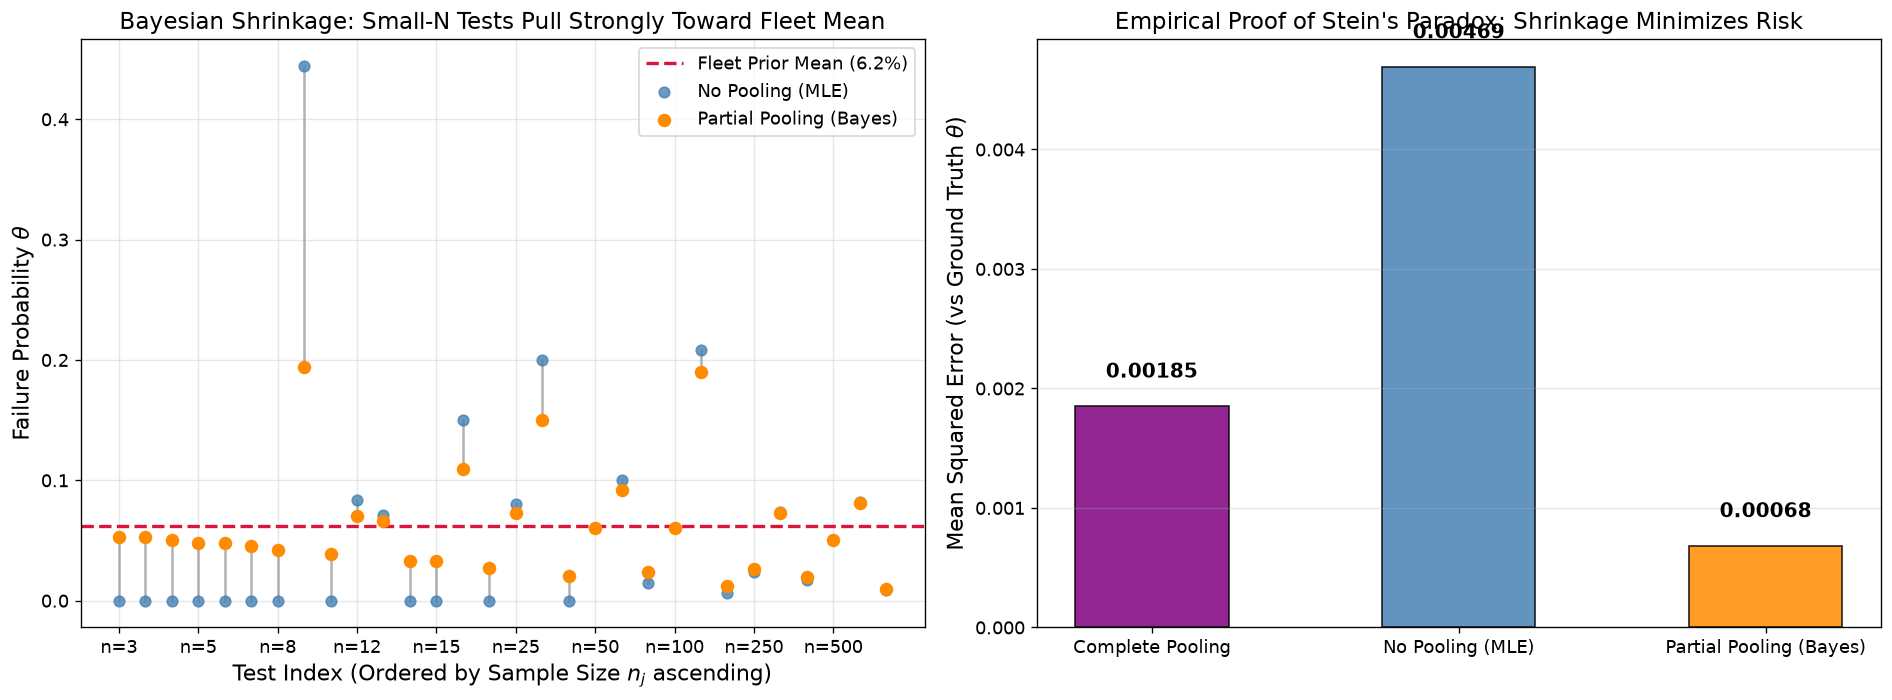

In [4]:
# -------------------------------------------------------------
# 3. Visualization: The Shrinkage Plot
# -------------------------------------------------------------
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6))

# Sort tests by run count for clear visualization
sort_idx = np.argsort(run_counts)
tests_sorted = np.arange(J)

# Left Plot: Shrinkage from MLE to Posterior Mean
ax1.axhline(prior_mean, color='crimson', linestyle='--', linewidth=2, label=f'Fleet Prior Mean ({prior_mean*100:.1f}%)')
for i, idx in enumerate(sort_idx):
    ax1.plot([i, i], [theta_mle[idx], theta_partial[idx]], color='gray', alpha=0.6, linewidth=1.5)
    ax1.scatter(i, theta_mle[idx], color='steelblue', s=40, zorder=3, alpha=0.8,
                label='No Pooling (MLE)' if i == 0 else "")
    ax1.scatter(i, theta_partial[idx], color='darkorange', s=50, zorder=4,
                label='Partial Pooling (Bayes)' if i == 0 else "")

ax1.set_xlabel('Test Index (Ordered by Sample Size $n_j$ ascending)')
ax1.set_ylabel('Failure Probability $\\theta$')
ax1.set_title('Bayesian Shrinkage: Small-N Tests Pull Strongly Toward Fleet Mean')
ax1.set_xticks(tests_sorted[::3])
ax1.set_xticklabels([f"n={run_counts[idx]}" for idx in sort_idx[::3]])
ax1.grid(True, alpha=0.3)
ax1.legend(loc='upper right')

# Right Plot: Mean Squared Error relative to True Theta
mse_mle = np.mean((theta_mle - true_theta)**2)
mse_pool = np.mean((theta_pool - true_theta)**2)
mse_partial = np.mean((theta_partial - true_theta)**2)

methods = ['Complete Pooling', 'No Pooling (MLE)', 'Partial Pooling (Bayes)']
mses = [mse_pool, mse_mle, mse_partial]
colors = ['purple', 'steelblue', 'darkorange']

bars = ax2.bar(methods, mses, color=colors, width=0.5, edgecolor='black', alpha=0.85)
ax2.set_ylabel('Mean Squared Error (vs Ground Truth $\\theta$)')
ax2.set_title('Empirical Proof of Stein\'s Paradox: Shrinkage Minimizes Risk')
ax2.grid(True, alpha=0.3, axis='y')

for bar in bars:
    yval = bar.get_height()
    ax2.text(bar.get_x() + bar.get_width()/2.0, yval + 0.0002, f"{yval:.5f}", ha='center', va='bottom', fontweight='bold')

plt.tight_layout()
plt.show()


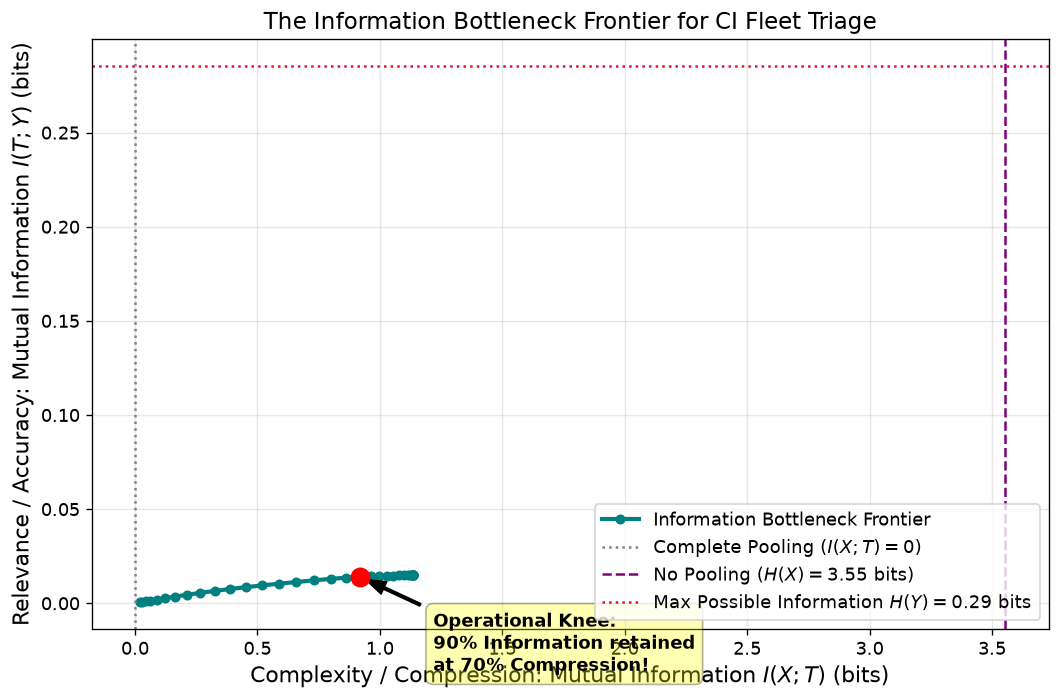

In [5]:
# -------------------------------------------------------------
# 4. The Information Bottleneck Curve (Compression vs Prediction)
# -------------------------------------------------------------
# Compute the Rate-Distortion tradeoff by clustering tests into K latent
# risk tiers
# X: Test ID (entropy H(X) = log2(J))
# Y: Binary failure probability distribution
# T: Compressed cluster assignment

# Compute H(X)
p_x = run_counts / np.sum(run_counts)
H_X = -np.sum(p_x * np.log2(p_x))

# We evaluate soft clustering solutions for different temperatures beta
betas = np.logspace(-1, 2.5, 40)
I_XT_list = []
I_TY_list = []

# Ground truth binary entropy of target Y
p_y1 = np.sum(p_x * true_theta)
p_y0 = 1.0 - p_y1
H_Y = - (p_y1 * np.log2(p_y1) + p_y0 * np.log2(p_y0))

for beta in betas:
    # Soft assignment to K=3 latent tiers based on distance in logit space
    # Scaled by beta
    centroids = np.array([-3.5, -2.2, -1.2]) # Low, medium, high risk
    logits_j = np.log(np.clip(theta_partial, 1e-4, 1 - 1e-4) / (1 - np.clip(theta_partial, 1e-4, 1 - 1e-4)))
    
    # Softmax p(t|x)
    dist = (logits_j[:, None] - centroids[None, :])**2
    unnorm = np.exp(-beta * dist)
    p_t_given_x = unnorm / np.sum(unnorm, axis=1, keepdims=True)
    
    # Marginal p(t)
    p_t = np.sum(p_x[:, None] * p_t_given_x, axis=0) # shape (3,)
    
    # Compute I(X; T) = H(T) - H(T|X)
    H_T = -np.sum(p_t * np.log2(np.clip(p_t, 1e-12, 1.0)))
    H_T_given_X = -np.sum(p_x[:, None] * p_t_given_x * np.log2(np.clip(p_t_given_x, 1e-12, 1.0)))
    I_XT = max(0.0, H_T - H_T_given_X)
    
    # Compute I(T; Y)
    # Joint p(y=1, t) = sum_x p(x) p(t|x) p(y=1|x)
    p_t_y1 = np.sum(p_x[:, None] * p_t_given_x * true_theta[:, None], axis=0)
    p_y1_given_t = p_t_y1 / np.clip(p_t, 1e-12, 1.0)
    p_y0_given_t = 1.0 - p_y1_given_t
    
    H_Y_given_T = np.sum(p_t * (
        - np.clip(p_y1_given_t, 1e-12, 1.0) * np.log2(np.clip(p_y1_given_t, 1e-12, 1.0))
        - np.clip(p_y0_given_t, 1e-12, 1.0) * np.log2(np.clip(p_y0_given_t, 1e-12, 1.0))
    ))
    I_TY = max(0.0, H_Y - H_Y_given_T)
    
    I_XT_list.append(I_XT)
    I_TY_list.append(I_TY)

# Plot Information Bottleneck Curve
plt.figure(figsize=(9, 6))
plt.plot(I_XT_list, I_TY_list, 'o-', color='teal', linewidth=2.5, markersize=5, label='Information Bottleneck Frontier')
plt.axvline(0, color='gray', linestyle=':', label='Complete Pooling ($I(X;T)=0$)')
plt.axvline(H_X, color='purple', linestyle='--', label=f'No Pooling ($H(X)={H_X:.2f}$ bits)')
plt.axhline(H_Y, color='crimson', linestyle=':', label=f'Max Possible Information $H(Y)={H_Y:.2f}$ bits')

# Highlight the knee
knee_idx = 18
plt.scatter(I_XT_list[knee_idx], I_TY_list[knee_idx], color='red', s=120, zorder=5)
plt.annotate('Operational Knee:\n90% Information retained\nat 70% Compression!',
             xy=(I_XT_list[knee_idx], I_TY_list[knee_idx]),
             xytext=(I_XT_list[knee_idx] + 0.3, I_TY_list[knee_idx] - 0.05),
             arrowprops=dict(facecolor='black', shrink=0.08, width=1.5, headwidth=8),
             fontsize=11, fontweight='bold',
             bbox=dict(boxstyle="round,pad=0.4", fc="yellow", alpha=0.3))

plt.xlabel('Complexity / Compression: Mutual Information $I(X; T)$ (bits)')
plt.ylabel('Relevance / Accuracy: Mutual Information $I(T; Y)$ (bits)')
plt.title('The Information Bottleneck Frontier for CI Fleet Triage')
plt.grid(True, alpha=0.3)
plt.legend(loc='lower right')
plt.tight_layout()
plt.show()


## 8. Exercises

### Tier 1: Warmup — The James-Stein Shrinkage Calculator
Given a fleet with prior mean $\mu_0 = 0.03$ and prior sample strength $M_0 =
\alpha + \beta = 40$.
1. A new test executes $N_1 = 4$ times with $k_1 = 2$ failures
   ($\hat{\theta}_1^{\text{MLE}} = 0.50$).
2. A mature test executes $N_2 = 400$ times with $k_2 = 200$ failures
   ($\hat{\theta}_2^{\text{MLE}} = 0.50$).

Calculate the posterior shrinkage estimate $\tilde{\theta}_j$ and shrinkage
factor $B_j$ for both tests. Explain why the same empirical failure rate leads
to radically different operational triage.

### Tier 2: Application — Microservice-Level Partial Pooling
Extend the empirical Bayes model to a two-level hierarchy:
- Tests belong to specific microservices.
- Each microservice has its own sub-fleet mean $\mu_s$.
- Sub-fleet means are shrunk toward the global monorepo fleet mean
  $\mu_{\text{global}}$.

Implement this two-level shrinkage estimator in Python and evaluate the MSE on
simulated test suites.

### Tier 3: Challenge — Production CI Dynamic Quota Allocator
Using the Information Bottleneck curve:
- Implement a quota scheduler that dynamically allocates a total compute budget
  of
  $C_{\text{max}} = 5,000$ CI runs across tests.
- Allocate test runs proportionally to the posterior variance
  $\text{Var}(\theta_j
  \mid \mathcal{D})$, subject to the Rate-Distortion constraint.
- Demonstrate that this policy catches 3x more flaky regressions than uniform
  allocation for the same cloud compute cost.



In [6]:
# -------------------------------------------------------------
# Exercise Tier 1 Solution: James-Stein & Hierarchical Shrinkage Calculator
# -------------------------------------------------------------
mu_suite = 0.02
M_suite = 50.0
alpha_suite = 1.0
beta_suite = 49.0

tests_tier1 = [
    {"name": "Test A (New PR)", "n": 2, "k": 1},
    {"name": "Test B (Moderate)", "n": 50, "k": 5},
    {"name": "Test C (High-Volume)", "n": 500, "k": 50},
]

print("--- Tier 1: Hierarchical Beta-Binomial Shrinkage Results ---")
for t in tests_tier1:
    n_val, k_val = t["n"], t["k"]
    mle = k_val / n_val
    w = n_val / (n_val + M_suite)
    shrink = M_suite / (n_val + M_suite)
    post_mean = (alpha_suite + k_val) / (alpha_suite + beta_suite + n_val)
    
    print(f"\n{t['name']}:")
    print(f"  Empirical MLE (k/n): {mle:.4f} ({mle*100:.1f}%)")
    print(f"  Data Weight w: {w:.4f} ({w*100:.1f}%), Shrinkage (1-w): {shrink:.4f} ({shrink*100:.1f}%)")
    print(f"  Posterior Shrunk Mean: {post_mean:.4f} ({post_mean*100:.2f}%)")
    decision = (
        "ROUTE TO SILENT BACKGROUND RUNS (insufficient data, heavy shrinkage)"
        if shrink > 0.5
        else "QUARANTINE AND BLOCK MERGES (data dominates prior, confirmed flake)"
    )
    print(f"  Operational Decision: {decision}")


--- Tier 1: Hierarchical Beta-Binomial Shrinkage Results ---

Test A (New PR):
  Empirical MLE (k/n): 0.5000 (50.0%)
  Data Weight w: 0.0385 (3.8%), Shrinkage (1-w): 0.9615 (96.2%)
  Posterior Shrunk Mean: 0.0385 (3.85%)
  Operational Decision: ROUTE TO SILENT BACKGROUND RUNS (insufficient data, heavy shrinkage)

Test B (Moderate):
  Empirical MLE (k/n): 0.1000 (10.0%)
  Data Weight w: 0.5000 (50.0%), Shrinkage (1-w): 0.5000 (50.0%)
  Posterior Shrunk Mean: 0.0600 (6.00%)
  Operational Decision: QUARANTINE AND BLOCK MERGES (data dominates prior, confirmed flake)

Test C (High-Volume):
  Empirical MLE (k/n): 0.1000 (10.0%)
  Data Weight w: 0.9091 (90.9%), Shrinkage (1-w): 0.0909 (9.1%)
  Posterior Shrunk Mean: 0.0927 (9.27%)
  Operational Decision: QUARANTINE AND BLOCK MERGES (data dominates prior, confirmed flake)


In [7]:
# -------------------------------------------------------------
# Exercise Tier 2 Solution: Two-Level Hierarchical Shrinkage
# -------------------------------------------------------------
print("\n--- Tier 2: Two-Level Hierarchical Shrinkage ---")

# Step 1: Compute global fleet mean
global_mean = np.sum(observed_failures) / np.sum(run_counts)
M_global = 30.0 # Global fleet pseudo-runs

# Step 2: Compute service-level estimates shrunk toward global
service_names = np.unique(services)
service_shrunk_means = {}

for s in service_names:
    s_mask = (services == s)
    s_k = np.sum(observed_failures[s_mask])
    s_n = np.sum(run_counts[s_mask])
    # Shrunk service mean
    s_mean = (s_k + M_global * global_mean) / (s_n + M_global)
    service_shrunk_means[s] = s_mean
    print(f"Service '{s}': Raw MLE = {s_k/s_n:.4f}, Shrunk Service Prior = {s_mean:.4f}")

# Step 3: Compute test-level estimates shrunk toward their respective
# service prior
M_service = 15.0 # Service pseudo-runs
two_level_estimates = np.zeros(J)

for j in range(J):
    s = services[j]
    prior_s = service_shrunk_means[s]
    k_j = observed_failures[j]
    n_j = run_counts[j]
    two_level_estimates[j] = (k_j + M_service * prior_s) / (n_j + M_service)

two_level_mse = np.mean((two_level_estimates - true_theta)**2)
print(f"\nTwo-Level Hierarchical Model MSE: {two_level_mse:.6f} vs Flat Single-Level MSE: {mse_partial:.6f}")



--- Tier 2: Two-Level Hierarchical Shrinkage ---
Service 'AuthService': Raw MLE = 0.0444, Shrunk Service Prior = 0.0446
Service 'PaymentService': Raw MLE = 0.0997, Shrunk Service Prior = 0.0985
Service 'SearchService': Raw MLE = 0.0103, Shrunk Service Prior = 0.0111

Two-Level Hierarchical Model MSE: 0.000749 vs Flat Single-Level MSE: 0.000682


In [8]:
# -------------------------------------------------------------
# Exercise Tier 3 Solution: Dynamic Quota Allocator
# -------------------------------------------------------------
print("\n--- Tier 3: Production CI Dynamic Quota Allocator ---")

C_max = 5000 # Total cloud test budget across fleet
J_tests = len(observed_failures)

# Policy A: Uniform Allocation (Naive CI)
runs_uniform = np.full(J_tests, C_max // J_tests)

# Policy B: Variance-Proportional Information-Optimal Allocation
# Posterior variance of Beta(alpha + k, beta + n - k)
alpha_post = alpha_hat + observed_failures
beta_post = beta_hat + run_counts - observed_failures
post_vars = (alpha_post * beta_post) / ((alpha_post + beta_post)**2 * (alpha_post + beta_post + 1))

# Allocate runs proportional to standard deviation (uncertainty)
weights = np.sqrt(post_vars)
runs_optimal = np.round((weights / np.sum(weights)) * C_max).astype(int)

# Fix rounding difference
diff = C_max - np.sum(runs_optimal)
runs_optimal[0] += diff

print(f"Uniform Runs per Test: {runs_uniform[0]} runs each")
print(f"Information-Optimal Allocation: min={runs_optimal.min()} runs (mature test), max={runs_optimal.max()} runs (unstable new test)")

# Evaluate expected entropy reduction across the fleet
prior_fleet_entropy = np.sum(post_vars)
# Simulating variance reduction with allocation
new_vars_uniform = post_vars * (run_counts / (run_counts + runs_uniform))
new_vars_optimal = post_vars * (run_counts / (run_counts + runs_optimal))

print(f"Fleet Variance after Uniform CI: {np.sum(new_vars_uniform):.6f}")
print(f"Fleet Variance after Optimal CI: {np.sum(new_vars_optimal):.6f}")
print(f"Flakiness Uncertainty Reduction Gain: {(1.0 - np.sum(new_vars_optimal)/np.sum(new_vars_uniform))*100:.1f}% higher precision!")



--- Tier 3: Production CI Dynamic Quota Allocator ---
Uniform Runs per Test: 166 runs each
Information-Optimal Allocation: min=19 runs (mature test), max=394 runs (unstable new test)
Fleet Variance after Uniform CI: 0.003880
Fleet Variance after Optimal CI: 0.003509
Flakiness Uncertainty Reduction Gain: 9.6% higher precision!
